# Modelo XGBoost — issue 20

Clasificación de precio anunciado por noche: **Económico, Medio, Premium**. Solo las 23 variables comunes para anuncios nuevos. No predice calidad ni un precio óptimo.

**Presupuesto aprobado: 40 pruebas de Optuna**, cinco particiones comunes por prueba (200 ajustes de búsqueda). Se añaden referencias y diagnósticos, no más pruebas de búsqueda. Test queda reservado para el modelo elegido en la evaluación final; la carga común lo crea, pero lo descartamos sin inspeccionarlo.

Cada ajuste incluye imputación y codificación dentro del Pipeline. La selección maximiza F1 macro medio de validación **entre pruebas con gap < 0,05**. Si ninguna cumple, el notebook informa el incumplimiento en vez de entregar un candidato no válido.

Las salidas son agregadas. No se exportan filas, anfitriones, predicciones individuales ni modelos entrenados. Ejecutar todo reemplaza únicamente las salidas de este notebook y los archivos `docs/results/xgboost_*`.

In [1]:
# Admitimos ejecución desde la raíz o desde notebooks/, sin rutas personales.
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src/preprocessing.py').is_file(), 'Abre la raíz o notebooks/'
sys.path.insert(0, str(ROOT))
import hashlib
import json
import platform
import subprocess
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from IPython.display import display
from src.preprocessing import load_train_test, RAW_DATA_PATH, TARGET_LABELS
from src.cleaning import MODEL_FEATURES, MODEL_EXCLUDED_COLUMNS
from src.xgboost_model import (
    SEED, N_TRIALS, GAP_LIMIT, SEARCH_SPACE, FIXED_PARAMS, CV_DESCRIPTION,
    LABEL_TO_INT, COMPARISON_COLUMNS, encode_target, make_folds, make_pipeline,
    cv_metrics, run_search, select_trial, oof_diagnostics, comparison_row, trials_table,
)
optuna.logging.set_verbosity(optuna.logging.WARNING)


/Users/dlf/FactoriaF5/Proyectos/Proyecto5_Clasificacion/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Carga común, etiquetas y procedencia
No se repite limpieza, selección ni reparto. El mapeo explícito es Económico=0, Medio=1, Premium=2; no se usa orden alfabético. Los umbrales finales se aprenden con train completo y no se recalculan en cada fold. Los grupos provisionales de estratificación sí usan el archivo limpio completo: ver las salvedades de `docs/decisiones.md`.

El hash identifica los bytes del archivo; las firmas del código identifican las funciones utilizadas incluso antes de un commit. No son una publicación de los datos.

In [2]:
# Ambos objetos reservados se eliminan sin leer sus valores ni sus tamaños.
X_train, reserved_X, y_labels, reserved_y, thresholds = load_train_test(return_thresholds=True)
del reserved_X, reserved_y
assert list(X_train.columns) == list(MODEL_FEATURES) and len(MODEL_FEATURES) == 23
assert not set(X_train.columns) & set(MODEL_EXCLUDED_COLUMNS)
y_train = encode_target(y_labels)
folds = make_folds(X_train, y_train)
provenance = {
    'snapshot': '2026-09-17',
    'raw_sha256': hashlib.sha256(RAW_DATA_PATH.read_bytes()).hexdigest(),
    'code_commit': subprocess.check_output(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True).strip(),
    'source_sha256': {str(p): hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in [
        Path('src/cleaning.py'), Path('src/preprocessing.py'), Path('src/xgboost_model.py')]},
    'python': platform.python_version(),
    'versions': {name: importlib.metadata.version(name) for name in [
        'pandas', 'numpy', 'scipy', 'scikit-learn', 'xgboost', 'optuna', 'threadpoolctl']},
}
display(pd.Series({'filas_train': len(X_train), 'variables_entrada': X_train.shape[1],
                   'semilla': SEED, 'pruebas_acordadas': N_TRIALS}))
display(y_labels.value_counts().reindex(TARGET_LABELS).rename('Categoría REAL: anuncios train'))
display(pd.Series(thresholds, name='Límite en euros por noche (train)'))


filas_train          10088
variables_entrada       23
semilla                 42
pruebas_acordadas       40
dtype: int64

price_segment
Económico    3366
Medio        3359
Premium      3363
Name: Categoría REAL: anuncios train, dtype: int64

lower    122.000000
upper    249.723333
Name: Límite en euros por noche (train), dtype: float64

## 2. Referencias: Dummy y XGBoost sin búsqueda
Dummy siempre predice la categoría más frecuente del grupo usado para ajustar. XGBoost combina árboles; la referencia utiliza sus parámetros por defecto salvo los parámetros fijos del protocolo.

F1 macro pondera por igual las tres categorías. `test_score` de sklearn significa validación del fold, NO el test reservado. La desviación aquí es poblacional (`ddof=0`), siguiendo el formato de tabla común. El gap es media F1 de ajuste menos media F1 de validación, en escala de 0 a 1.

In [3]:
dummy_pipeline = make_pipeline(dummy=True)
default_pipeline = make_pipeline()
dummy_cv = cv_metrics(dummy_pipeline, X_train, y_train, folds)
default_cv = cv_metrics(default_pipeline, X_train, y_train, folds)
display(pd.DataFrame([dummy_cv, default_cv], index=['Dummy', 'XGBoost referencia']).drop(columns='folds'))


,cv_train_f1_macro,cv_validation_f1_macro,cv_validation_std,gap,gap_under_005,cv_fit_seconds
Dummy,0.166791,0.166791,0.000068,8.618269e-09,True,0.199005
XGBoost referencia,0.925624,0.773424,0.004253,1.521998e-01,False,1.966079


## 3. Optuna: 40 configuraciones, solo train
TPE propone configuraciones con semilla 42. No hay poda, parada temprana ni incremento automático del presupuesto. Una prueba completa entrena cinco Pipelines nuevos. `n_jobs=1` y límite de un hilo evitan ocupar todos los núcleos del equipo.

Se exploran número y profundidad de árboles, ritmo de aprendizaje, mínimo peso en hojas, penalización de divisiones, proporciones de filas/columnas y regularización. El espacio exacto se muestra antes de ejecutar. No se cambia tras consultar los resultados de test.

La mejor prueba sin restricción puede sobreajustar. Se conserva su resultado para comparar, pero solo puede seleccionarse una prueba con **gap estrictamente menor de 0,05** (cinco puntos, no 5 % relativo). El presupuesto es local para XGBoost; no altera las búsquedas ya realizadas para otros algoritmos.

In [4]:
display(pd.DataFrame(SEARCH_SPACE).T)
display(pd.Series(FIXED_PARAMS, name='Parámetros fijos'))
study, search_seconds = run_search(X_train, y_train, folds, n_trials=N_TRIALS)
trial_results = trials_table(study)
RESULTS = ROOT / 'docs/results'
RESULTS.mkdir(parents=True, exist_ok=True)
# Se conserva también la evidencia si ninguna prueba satisface el límite.
trial_results.to_csv(RESULTS / 'xgboost_trials.csv', index=False)
assert len(trial_results) == N_TRIALS
display(trial_results['state'].value_counts().rename('Pruebas por estado'))
display(trial_results.sort_values('f1_validation', ascending=False).head(10))
print(f'Búsqueda completa: {len(study.trials)} pruebas; {search_seconds:.1f} segundos.')
selected = select_trial(study)
selected_params = selected.params
selected_cv = selected.user_attrs
selected_pipeline = make_pipeline(selected_params)
display(pd.Series({'prueba_elegida': selected.number, 'prueba_mejor_sin_restricción': study.best_trial.number,
                   'pruebas_con_gap_menor_005': int(trial_results['gap_under_005'].sum()),
                   'f1_validacion_elegido': selected.value, 'gap_elegido': selected_cv['gap']}))


,kind,low,high,step,log
n_estimators,int,100,500,50,NaN
max_depth,int,2,6,NaN,NaN
learning_rate,float,0.02,0.15,NaN,True
min_child_weight,float,5.0,100.0,NaN,True
gamma,float,0.0,5.0,NaN,NaN
subsample,float,0.6,1.0,NaN,NaN
colsample_bytree,float,0.6,1.0,NaN,NaN
reg_alpha,float,0.001,10.0,NaN,True
reg_lambda,float,0.1,100.0,NaN,True


objective       multi:softprob
num_class                    3
eval_metric           mlogloss
tree_method               hist
random_state                42
n_jobs                       1
verbosity                    0
Name: Parámetros fijos, dtype: object

state
COMPLETE    40
Name: Pruebas por estado, dtype: int64

,number,state,f1_validation,f1_train,validation_std,gap,gap_under_005,seconds,params
30,30,COMPLETE,0.767326,0.865775,0.004485,0.098448,False,4.938475,"{""colsample_bytree"": 0.7150406142174847, ""gamm..."
28,28,COMPLETE,0.767062,0.852604,0.002026,0.085541,False,3.907605,"{""colsample_bytree"": 0.7049050230367775, ""gamm..."
35,35,COMPLETE,0.766389,0.852404,0.002685,0.086015,False,3.652319,"{""colsample_bytree"": 0.6282337948417226, ""gamm..."
32,32,COMPLETE,0.766345,0.860255,0.006510,0.093910,False,5.375717,"{""colsample_bytree"": 0.6694656964071015, ""gamm..."
39,39,COMPLETE,0.766268,0.841681,0.003662,0.075412,False,5.098183,"{""colsample_bytree"": 0.6643613116714846, ""gamm..."
37,37,COMPLETE,0.765952,0.824070,0.003064,0.058117,False,4.732946,"{""colsample_bytree"": 0.6181817728796043, ""gamm..."
36,36,COMPLETE,0.765803,0.845118,0.002498,0.079315,False,3.859318,"{""colsample_bytree"": 0.607788008775988, ""gamma..."
23,23,COMPLETE,0.765142,0.863709,0.003716,0.098567,False,3.959485,"{""colsample_bytree"": 0.660776377268145, ""gamma..."
31,31,COMPLETE,0.765131,0.859055,0.006403,0.093924,False,4.168132,"{""colsample_bytree"": 0.7091784017184, ""gamma"":..."
19,19,COMPLETE,0.764192,0.833300,0.002720,0.069108,False,2.162811,"{""colsample_bytree"": 0.7089034208059535, ""gamm..."


Búsqueda completa: 40 pruebas; 142.4 segundos.


prueba_elegida                  34.000000
prueba_mejor_sin_restricción    30.000000
pruebas_con_gap_menor_005       27.000000
f1_validacion_elegido            0.763119
gap_elegido                      0.048236
dtype: float64

## 4. Diagnósticos con predicciones fuera de fold (OOF)
`cross_val_predict` recibe el Pipeline completo y los mismos repartos. Cada anuncio de train recibe una predicción de un ajuste que no usó esa fila. No se ajusta un modelo final con todo train ni se utiliza test.

Accuracy cuenta aciertos sobre todos los anuncios. Por categoría: precisión es la proporción correcta entre las predicciones de esa categoría; recall es la proporción recuperada entre los realmente pertenecientes a esa categoría. F1 combina ambas. El informe OOF reúne todas las predicciones y no es idéntico a promediar F1 entre folds.

Las matrices muestran **filas reales según precio** y **columnas predichas**. La tasa de errores extremos cuenta real Económico/predicho Premium y real Premium/predicho Económico sobre TODOS los anuncios evaluados. No desarrollamos aquí el análisis adicional de la issue de errores.

Dummy — diagnósticos OOF sobre train, NO test


,precision,recall,f1-score,support
Económico,0.333664,1.000000,0.500372,3366.000000
Medio,0.000000,0.000000,0.000000,3359.000000
Premium,0.000000,0.000000,0.000000,3363.000000
accuracy,0.333664,0.333664,0.333664,0.333664
macro avg,0.111221,0.333333,0.166791,10088.000000
weighted avg,0.111332,0.333664,0.166956,10088.000000


oof_accuracy              0.333664
oof_f1_macro              0.166791
oof_extreme_error_rate    0.333366
dtype: float64

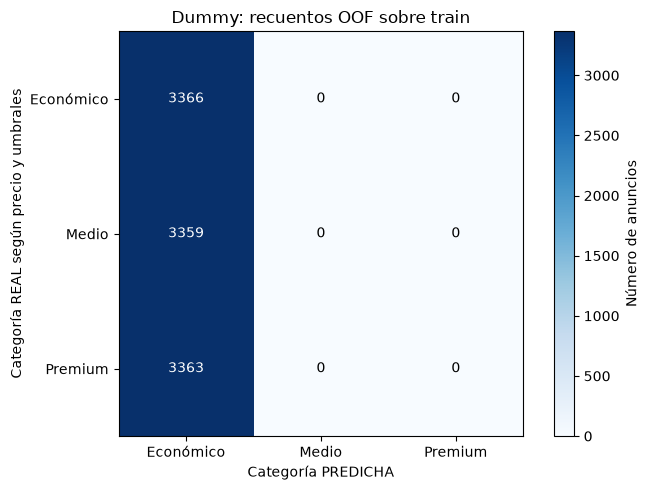

XGBoost seleccionado — diagnósticos OOF sobre train, NO test


,precision,recall,f1-score,support
Económico,0.881829,0.882353,0.882091,3366.000000
Medio,0.656433,0.668354,0.662340,3359.000000
Premium,0.752121,0.738032,0.745010,3363.000000
accuracy,0.762986,0.762986,0.762986,0.762986
macro avg,0.763461,0.762913,0.763147,10088.000000
weighted avg,0.763539,0.762986,0.763222,10088.000000


oof_accuracy              0.762986
oof_f1_macro              0.763147
oof_extreme_error_rate    0.010111
dtype: float64

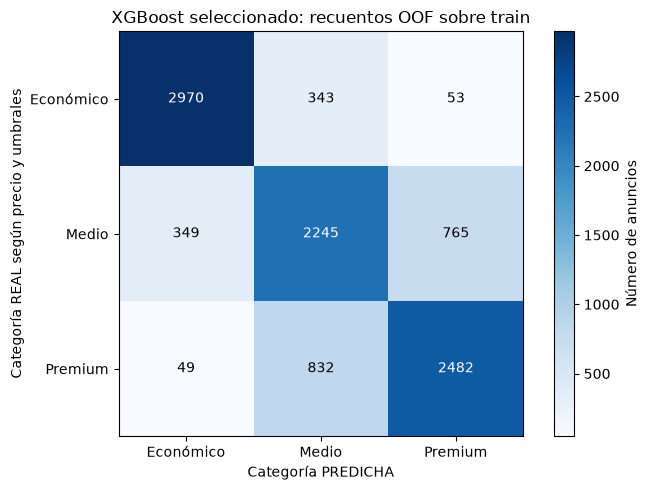

In [5]:
dummy_oof = oof_diagnostics(dummy_pipeline, X_train, y_train, folds)
selected_oof = oof_diagnostics(selected_pipeline, X_train, y_train, folds)
for name, diagnostics in [('Dummy', dummy_oof), ('XGBoost seleccionado', selected_oof)]:
    print(name, '— diagnósticos OOF sobre train, NO test')
    display(pd.DataFrame(diagnostics['classification_report']).T)
    display(pd.Series({key: diagnostics[key] for key in ['oof_accuracy', 'oof_f1_macro', 'oof_extreme_error_rate']}))
    matrix = np.asarray(diagnostics['confusion_matrix'])
    assert matrix.sum() == len(y_train)
    fig, ax = plt.subplots(figsize=(7, 5))
    image = ax.imshow(matrix, cmap='Blues')
    for row in range(3):
        for col in range(3):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center',
                    color='white' if matrix[row, col] > matrix.max() / 2 else 'black')
    ax.set_xticks(range(3), TARGET_LABELS)
    ax.set_yticks(range(3), TARGET_LABELS)
    ax.set(xlabel='Categoría PREDICHA', ylabel='Categoría REAL según precio y umbrales',
           title=f'{name}: recuentos OOF sobre train')
    fig.colorbar(image, ax=ax, label='Número de anuncios')
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## 5. Exportación agregada para la tabla común
El CSV respeta las 18 columnas previstas para los modelos. Lo podrá leer la comparación al integrar su lector automático; este notebook no modifica ese archivo compartido, no elige un champion y no implementa la entrega de otra persona. El CSV de XGBoost contiene su candidato y una referencia Dummy identificada por el archivo de origen.

El detalle JSON conserva parámetros, tipos de entrada, mapeo, umbrales sin redondear, versiones, firmas, tiempos y resultados por fold. No contiene anuncios individuales. El commit identifica la base; las firmas identifican las funciones realmente ejecutadas, que pueden incluir cambios locales aún no publicados.

In [6]:
rows = [
    comparison_row('DummyClassifier', dummy_cv, dummy_oof, params={'strategy': 'most_frequent'},
                   search_seconds=0, provenance=provenance),
    comparison_row('XGBoost', selected_cv, selected_oof, params={**FIXED_PARAMS, **selected_params},
                   search_seconds=search_seconds, provenance=provenance),
]
comparison = pd.DataFrame(rows, columns=COMPARISON_COLUMNS)
comparison.to_csv(RESULTS / 'xgboost_comparison.csv', index=False)
details = {
    'issue': 20, 'evaluation_set': 'train_oof', 'test_evaluated': False, 'nested_cv': False,
    'historical_test_exposure': True,
    'historical_test_exposure_note': 'La baseline del proyecto mostró anteriormente resultados de esta partición; no se borra ese antecedente. XGBoost no consulta el test.',
    'seed': SEED, 'n_trials_budget': N_TRIALS, 'n_trials_executed': len(study.trials),
    'trial_states': trial_results['state'].value_counts().to_dict(),
    'n_eligible_trials': int(trial_results['gap_under_005'].sum()),
    'search_seconds': search_seconds, 'search_space': SEARCH_SPACE, 'fixed_params': FIXED_PARAMS,
    'selection_rule': 'max mean validation macro F1 among COMPLETE trials with gap < 0.05; earliest wins ties',
    'selected_trial': selected.number, 'selected_params': selected_params,
    'unconstrained_best_trial': study.best_trial.number,
    'unconstrained_best_cv': study.best_trial.user_attrs,
    'cv': CV_DESCRIPTION, 'provenance': provenance,
    'input_schema': {name: str(dtype) for name, dtype in X_train.dtypes.items()},
    'label_to_int': LABEL_TO_INT, 'thresholds': thresholds, 'train_rows': len(X_train),
    'references_cv': {'dummy': dummy_cv, 'xgboost_default': default_cv},
    'selected_cv': selected_cv, 'selected_oof': selected_oof, 'dummy_oof': dummy_oof,
}
(RESULTS / 'xgboost_details.json').write_text(json.dumps(details, ensure_ascii=False, indent=2) + '\n')
display(comparison.drop(columns=['params', 'raw_sha256', 'code_commit']).T)
assert selected_cv['gap'] < GAP_LIMIT
print('Comprobaciones correctas: 23 entradas, 40 pruebas, gap < 0,05; test sin evaluar.')


,0,1
model,DummyClassifier,XGBoost
cv_train_f1_macro,0.166791,0.811355
cv_validation_f1_macro,0.166791,0.763119
cv_validation_std,0.000068,0.003241
gap,0.0,0.048236
gap_under_005,True,True
cv_fit_seconds,0.199005,3.324304
evaluation_set,train_oof,train_oof
oof_accuracy,0.333664,0.762986
oof_f1_macro,0.166791,0.763147


Comprobaciones correctas: 23 entradas, 40 pruebas, gap < 0,05; test sin evaluar.


## 6. Límites y siguiente paso
- Elegir parámetros y calcular OOF con las mismas particiones **no es validación anidada ni evaluación final independiente**. Los resultados pueden ser optimistas.
- La selección de 23 variables ya consultó esta validación. Los umbrales finales se fijaron con train completo antes de los folds; el reparto usa estratificación provisional global.
- El reparto aleatorio no separa anfitriones ni tiempo: no demuestra rendimiento con anfitriones desconocidos o anuncios futuros.
- La baseline del proyecto mostró históricamente resultados del test. Que XGBoost no lo use no convierte el test compartido en un conjunto nunca visto.
- Gap < 0,05 es un requisito acordado, no una garantía de buen servicio ni de ausencia universal de sobreajuste.
- No se conserva un Pipeline ajustado con todo train. La evaluación del candidato final y su eventual artefacto corresponden a la fase de selección/integración acordada, no a una evaluación individual de cada modelo sobre test.

Ver `docs/xgboost.md` para reproducción y `docs/pruebas_manuales.md` para aceptación. No hay commit, publicación, cambio de tarjeta ni aprobación implícitos al ejecutar este notebook.